# Lithium-Ion Battery State-of-Health Prediction Using Linear, Ridge, and Lasso Regression

## 1. Introduction

Lithium-ion batteries are widely used in electric vehicles, portable electronic devices, renewable energy storage systems, and other modern electrical applications. Their popularity is due to their high energy density, rechargeable characteristics, and relatively long operating life.

However, repeated charging and discharging gradually reduce battery performance and storage capacity. This degradation affects battery reliability, efficiency, and overall lifespan.

Battery State of Health (SOH) is an important indicator used to assess the remaining performance of a battery compared with its original condition. Accurate SOH estimation can support battery monitoring, maintenance planning, and Battery Management System (BMS) applications.

This project investigates the application of Linear Regression, Ridge Regression, and Lasso Regression to estimate lithium-ion battery SOH using experimental battery measurements and operating parameters.

Particular attention is given to regularization techniques because battery measurements may contain correlated features. Ridge and Lasso are investigated to understand how regularization affects model performance, coefficient stability, and feature selection.

## 2. Problem Statement

Lithium-ion battery degradation is influenced by several operating parameters, including temperature, voltage, current, and charging/discharging conditions. These parameters may have complex relationships and correlations with one another.

Ordinary Linear Regression can become sensitive to multicollinearity, potentially resulting in unstable coefficient estimates.

This project investigates whether Ridge and Lasso regularization can improve the stability and predictive performance of a linear regression model for battery SOH estimation.

### Research Objectives

1. Investigate the relationship between battery operating parameters and SOH.
2. Analyze correlations and multicollinearity among independent variables.
3. Develop a baseline Linear Regression model.
4. Apply Ridge Regression to control coefficient magnitude.
5. Apply Lasso Regression to perform regularization and feature selection.
6. Compare the performance of all three models.

### Research Questions

- How do battery operating parameters relate to battery SOH?
- Does multicollinearity affect ordinary Linear Regression?
- How does Ridge Regression influence coefficient stability?
- Which features are eliminated by Lasso Regression?
- Which regularization technique provides better predictive performance?
- How does the regularization parameter (alpha) affect model performance?

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

## 3. Data Loading and Initial Inspection

Before performing statistical analysis or developing regression models, it is important to understand the structure and quality of the dataset.

This stage focuses on examining the dataset dimensions, column names, data types, numerical distributions, and overall data completeness.

The initial inspection will help identify potential data quality issues that may affect subsequent analysis and model performance.

### Key Inspection Activities

- Examine the dataset shape.
- Identify numerical and categorical columns.
- Check missing values.
- Identify duplicate records.
- Review descriptive statistics.
- Investigate unusual or inconsistent measurements.


In [82]:
dataset = pd.read_excel(r"SoH Data with Temp.xlsx", sheet_name='Sheet2')
dataset.head(3)

,Battery type,Temp,Vdrop,Load Current,Vmin,Vvariance,Cycle number,Discharge Ah,Soh
0,5,24,2.7,2,2.612467,0.049531,1,1.861941,100.000000
1,5,24,2.7,2,2.587209,0.049057,2,1.851764,99.453403
2,5,24,2.7,2,2.651917,0.046841,3,1.838948,98.765117


In [83]:
df = dataset.drop(columns=['Battery type', 'Discharge Ah'])
df.head(3)

,Temp,Vdrop,Load Current,Vmin,Vvariance,Cycle number,Soh
0,24,2.7,2,2.612467,0.049531,1,100.000000
1,24,2.7,2,2.587209,0.049057,2,99.453403
2,24,2.7,2,2.651917,0.046841,3,98.765117


In [84]:
# Examine dataset shape
df.shape

(1942, 7)

In [85]:
# Check the data types
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1942 entries, 0 to 1941
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Temp          1942 non-null   int64  
 1   Vdrop         1942 non-null   float64
 2   Load Current  1942 non-null   int64  
 3   Vmin          1942 non-null   float64
 4   Vvariance     1942 non-null   float64
 5   Cycle number  1942 non-null   int64  
 6   Soh           1942 non-null   float64
dtypes: float64(4), int64(3)
memory usage: 106.3 KB


In [86]:
# Check for missing values
df.isnull().sum()

Temp            0
Vdrop           0
Load Current    0
Vmin            0
Vvariance       0
Cycle number    0
Soh             0
dtype: int64

In [87]:
# Identify duplicate records
df.duplicated().sum()

np.int64(0)

In [88]:
# Review descriptive statistics
df.describe()

,Temp,Vdrop,Load Current,Vmin,Vvariance,Cycle number,Soh
count,1942.000000,1942.000000,1942.000000,1942.000000,1942.000000,1942.000000,1942.000000
mean,23.658599,2.403399,2.715242,2.629681,0.089486,69.144696,82.929657
std,9.611266,0.254032,1.096463,0.427158,0.095066,51.790110,21.210249
min,4.000000,2.000000,1.000000,0.062889,0.004569,1.000000,3.611325
25%,24.000000,2.200000,2.000000,2.199514,0.046484,24.000000,79.766599
50%,24.000000,2.500000,2.000000,2.656689,0.059484,59.000000,88.608044
75%,24.000000,2.700000,4.000000,2.979525,0.081920,107.000000,95.574015
max,44.000000,2.700000,4.000000,3.757563,1.631267,196.000000,135.070714


## 4. Data Cleaning and Preprocessing

Data preprocessing is an essential step in developing reliable machine learning models. Raw experimental datasets may contain missing observations, duplicate records, inconsistent data types, and unusual measurements.

In this stage, the dataset will be examined and cleaned to improve data quality.

Special attention will be given to feature scaling because Ridge and Lasso regression apply penalties to model coefficients. Without standardization, features with larger numerical scales may disproportionately influence the regularization process.

The dataset will also be divided into training and testing subsets to evaluate model performance on unseen observations.

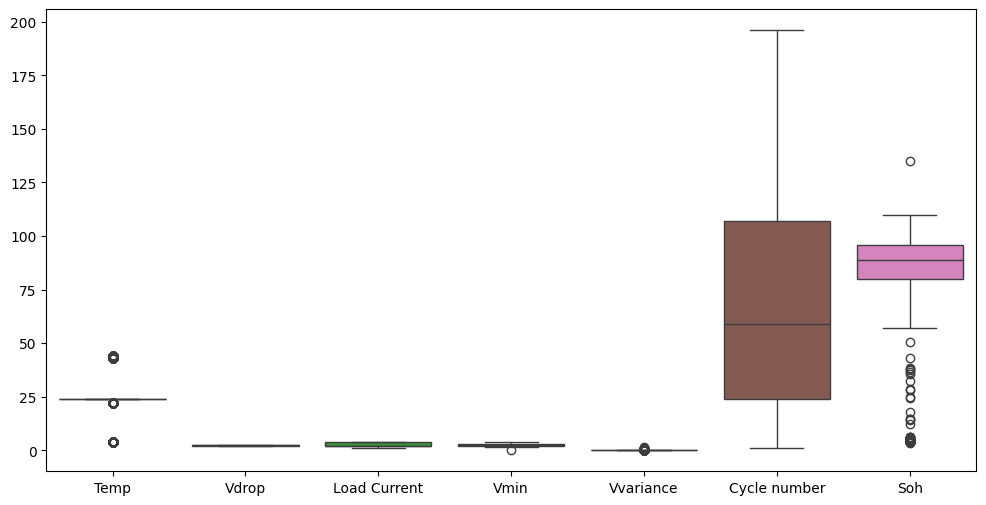

In [89]:
# Check outliers
plt.figure(figsize=(12, 6))
sns.boxplot(data=df)
plt.show()

In [90]:
# Remove outliers from all columns using IQR method through loop

for i in df.select_dtypes(include=np.number).columns:
    q1 = df[i].quantile(0.25)
    q3 = df[i].quantile(0.75)
    iqr = q3 - q1
    min_range = q1 - (1.5*iqr)
    max_range = q3 + (1.5*iqr)
    df = df[(df[i] >= min_range) & (df[i] <= max_range)]

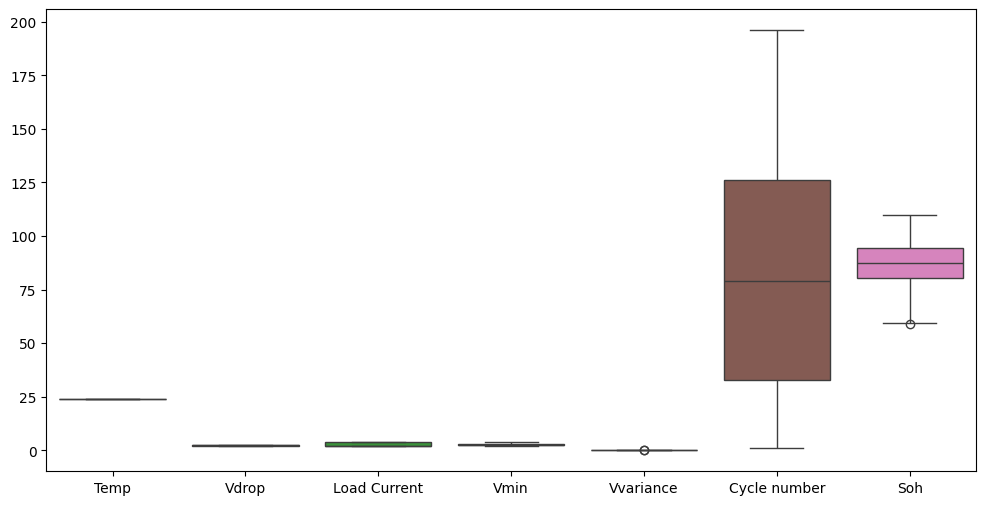

In [92]:
# Check outliers again, if there is any
plt.figure(figsize=(12, 6))
sns.boxplot(data=df)
plt.show()

## 5. Exploratory Data Analysis (EDA)

Exploratory Data Analysis is performed to understand the statistical characteristics of the battery dataset and identify relationships between operating parameters and battery State of Health.

This stage provides an initial understanding of battery degradation patterns and helps identify potentially useful predictors for regression modeling.

### Analysis Objectives

1. Examine the distribution of battery SOH.
2. Investigate battery degradation across aging cycles.
3. Analyze relationships between voltage, current, temperature, and SOH.
4. Understand the distribution and variability of independent variables.

The visual findings will be used to develop an informed understanding of the dataset before applying regression techniques.

C:\Users\riazu\AppData\Local\Temp\ipykernel_6860\3483308760.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df['Soh'], kde=True)


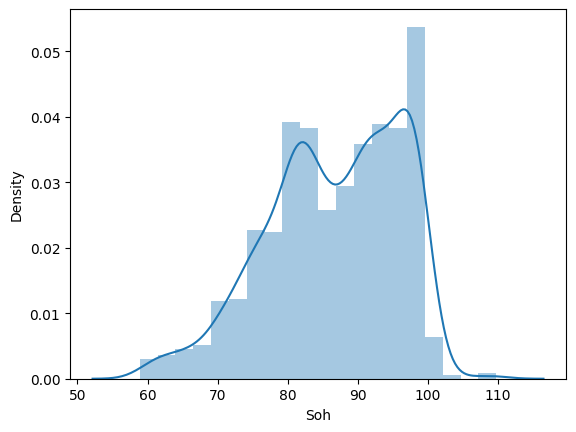

In [93]:
sns.distplot(df['Soh'], kde=True)
plt.show()

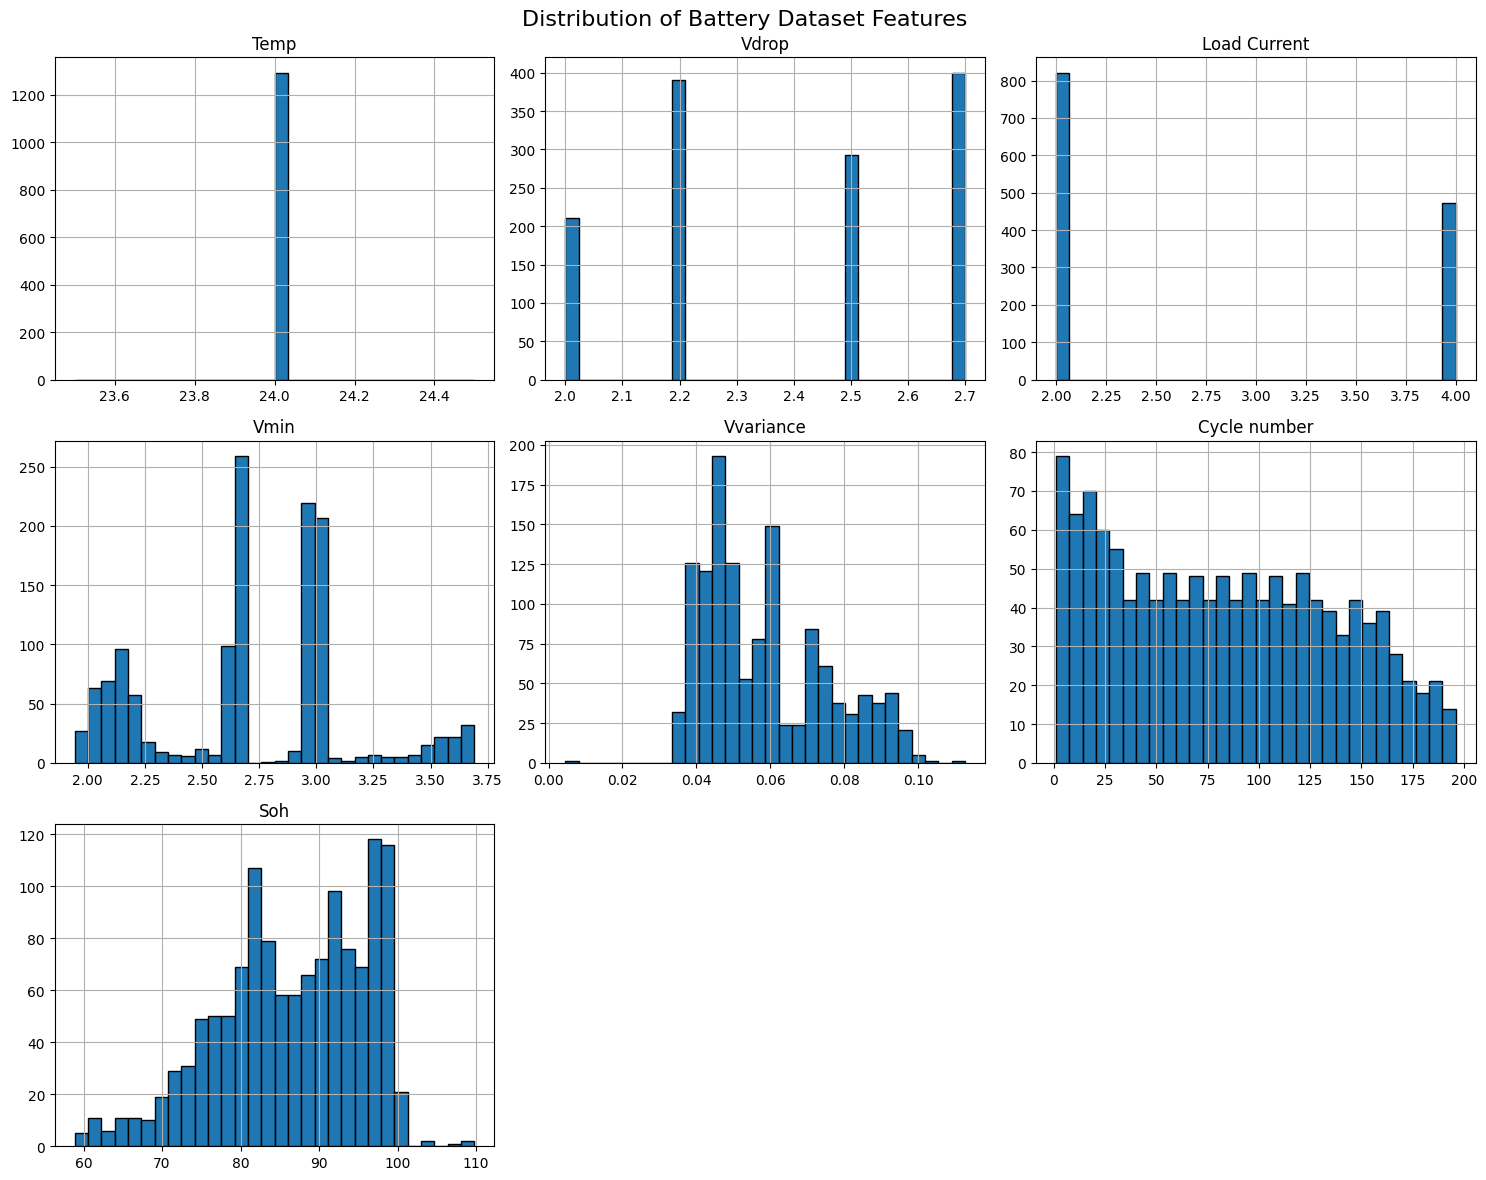

In [94]:
# Plot histograms
df.hist(
    bins=30,
    figsize=(15, 12),
    edgecolor='black'
)

plt.suptitle('Distribution of Battery Dataset Features', fontsize=16)
plt.tight_layout()
plt.show()

C:\Users\riazu\AppData\Local\Temp\ipykernel_6860\3679064296.py:12: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(title='Battery Type', bbox_to_anchor=(1.05, 1))


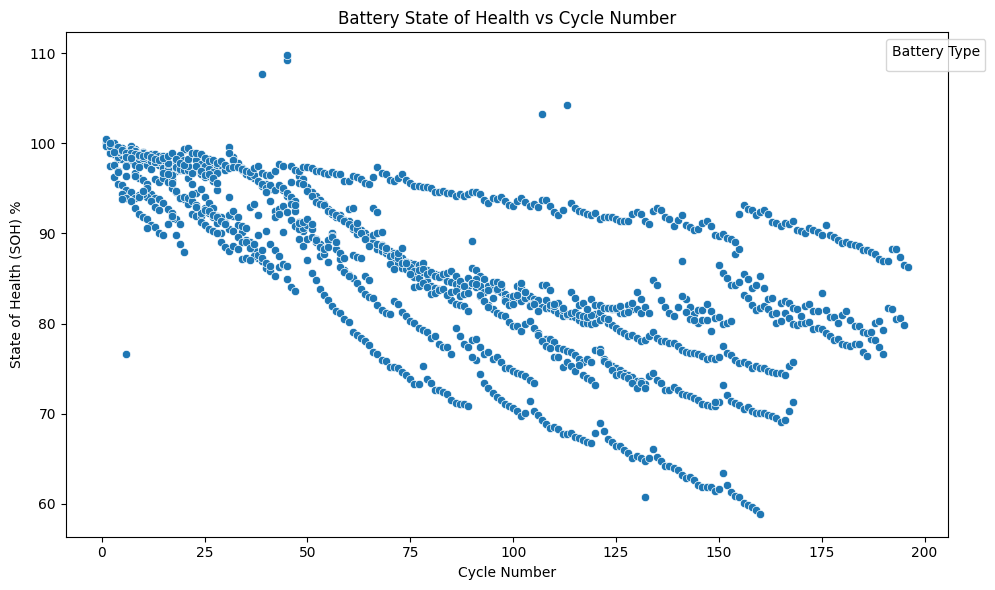

In [96]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='Cycle number',
    y='Soh'
)

plt.title('Battery State of Health vs Cycle Number')
plt.xlabel('Cycle Number')
plt.ylabel('State of Health (SOH) %')
plt.legend(title='Battery Type', bbox_to_anchor=(1.05, 1))
plt.tight_layout()
plt.show()

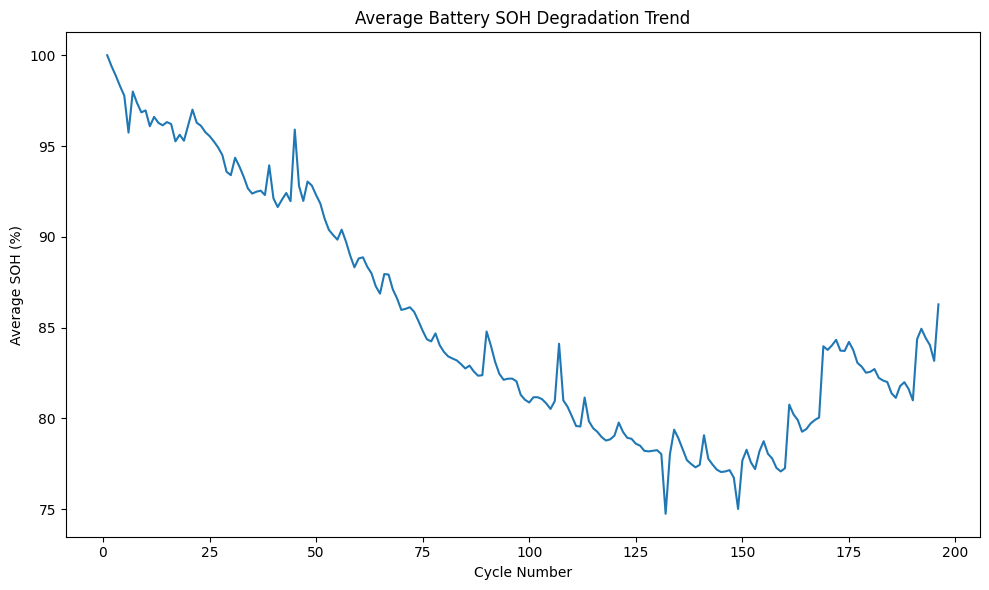

In [97]:
plt.figure(figsize=(10, 6))

sns.lineplot(
    data=df,
    x='Cycle number',
    y='Soh',
    estimator='mean',
    errorbar=None
)

plt.title('Average Battery SOH Degradation Trend')
plt.xlabel('Cycle Number')
plt.ylabel('Average SOH (%)')
plt.tight_layout()
plt.show()

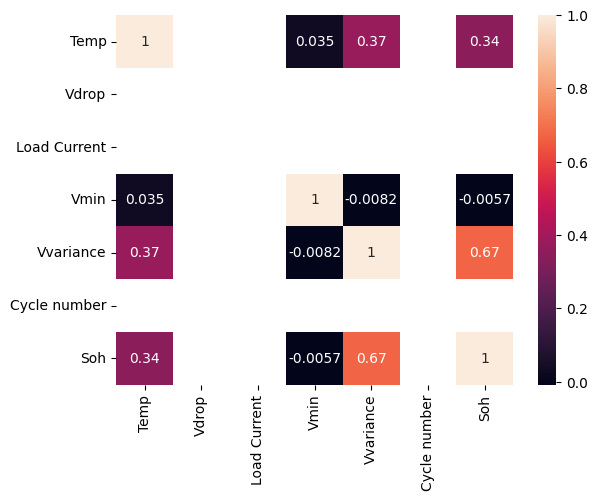

In [54]:
sns.heatmap(df.corr(), annot=True)
plt.show()

## 6. Feature Selection and Target Definition

The objective of this project is to estimate battery State of Health using relevant battery operating measurements.

The target variable is defined as SOH, while the independent variables consist of selected operating and measurement parameters.


In [103]:
# Create input and output variables
x = df.iloc[:, :-1]
y = df['Soh']


In [104]:
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

In [105]:
# Feature Scaling
sc = StandardScaler()
sc.fit(x)
x = pd.DataFrame(sc.transform(x), columns=x.columns)
x

,Temp,Vdrop,Load Current,Vmin,Vvariance,Cycle number
0,0.0,1.188344,-0.759030,-0.216162,-0.526489,-1.509287
1,0.0,1.188344,-0.759030,-0.274785,-0.554523,-1.490712
2,0.0,1.188344,-0.759030,-0.124603,-0.685494,-1.472138
3,0.0,1.188344,-0.759030,-0.261464,-0.580678,-1.453563
4,0.0,1.188344,-0.759030,-0.367131,-0.504389,-1.434988
...,...,...,...,...,...,...
1289,0.0,1.188344,1.317471,-0.058305,0.350903,-1.397838
1290,0.0,1.188344,1.317471,-0.043740,0.402205,-1.379263
1291,0.0,1.188344,1.317471,-0.071754,0.641256,-1.360688
1292,0.0,1.188344,1.317471,-0.044827,0.499622,-1.342113


## 7. Baseline Linear Regression Model

Linear Regression is used as the baseline predictive model for estimating lithium-ion battery State of Health.

The model establishes a relationship between selected battery operating parameters and SOH by estimating regression coefficients using the Ordinary Least Squares method.

The objective of this stage is to evaluate the predictive capability of an unregularized linear model before introducing penalty-based techniques.

### Evaluation Objectives

1. Establish baseline prediction performance.
2. Examine the estimated regression coefficients.
3. Analyze actual versus predicted SOH values.
4. Investigate residual patterns.
5. Identify potential instability associated with correlated predictors.

The results obtained from this model will serve as a reference for evaluating the effectiveness of Ridge and Lasso regularization.

In [106]:
# split dataset into training and testing sets
x_train, x_test, y_train, y_test = train_test_split(x,y, test_size=0.2, random_state=42)

In [107]:
from sklearn.linear_model import LinearRegression, Lasso, Ridge

In [143]:
lr = LinearRegression()
lr.fit(x_train, y_train)
lr_r2 = lr.score(x_test, y_test)
lr_r2

0.7027667201173438

In [109]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

In [142]:
lr_mse = mean_squared_error(y_test, lr.predict(x_test))
lr_mae = mean_absolute_error(y_test, lr.predict(x_test))
lr_rmse = np.sqrt(mean_squared_error(y_test, lr.predict(x_test)))

print('Linear Regression MSE: ', lr_mse)
print('Linear Regression MAE: ', lr_mae)
print('Linear Regression RMSE: ', lr_rmse)

Linear Regression MSE:  26.83972161058087
Linear Regression MAE:  3.9837519596236546
Linear Regression RMSE:  5.180706670964963


In [111]:
lr.coef_

array([ 0.        ,  1.4585532 ,  3.02498544, -4.92639696, -4.82537462,
       -5.82250055])

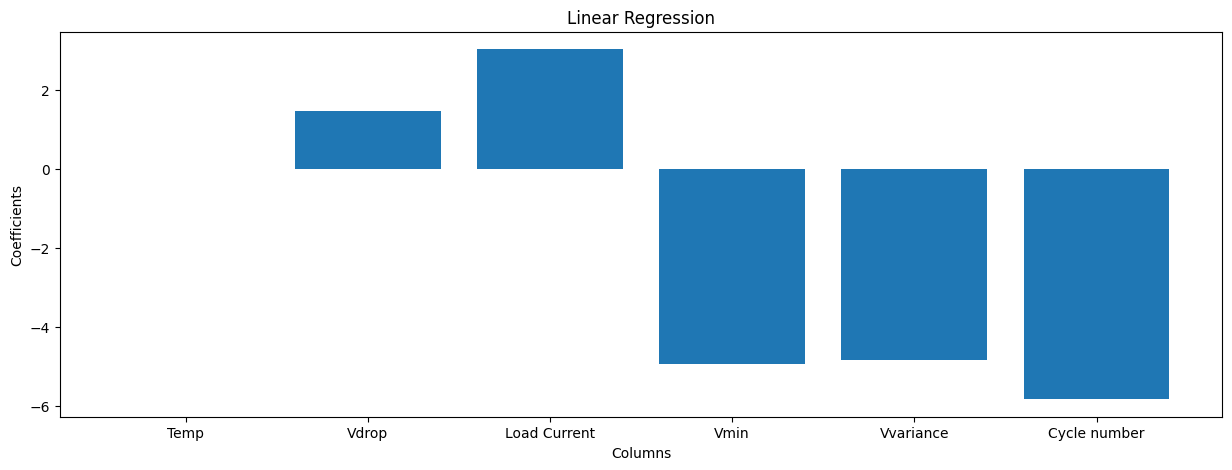

In [112]:
# Plot/display the coefficients
plt.figure(figsize=(15,5))
plt.bar(x.columns, lr.coef_)
plt.title('Linear Regression')
plt.xlabel('Columns')
plt.ylabel('Coefficients')
plt.show()

## 8. Ridge Regression (L2 Regularization)

Ridge Regression is a regularized version of Linear Regression that introduces an L2 penalty to the ordinary least-squares objective function.

The penalty reduces the magnitude of regression coefficients, helping control model complexity and improve coefficient stability when independent variables are highly correlated.

Unlike Lasso Regression, Ridge generally retains all selected features while shrinking their coefficients toward zero.

### Experimental Objectives

1. Apply L2 regularization to the selected predictors.
2. Investigate different alpha values.
3. Use cross-validation to identify a suitable regularization strength.
4. Examine changes in regression coefficients.
5. Compare Ridge performance with baseline Linear Regression.

### Expected Investigation

The experiment will examine whether Ridge Regression provides more stable coefficient estimates and better predictive performance than ordinary Linear Regression.

In [144]:
ri = Ridge(alpha=10)
ri.fit(x_train, y_train)
ri_r2 = ri.score(x_test, y_test)
ri_r2

0.7028328869505993

In [145]:
ri_mse = mean_squared_error(y_test, ri.predict(x_test))
ri_mae = mean_absolute_error(y_test, ri.predict(x_test))
ri_rmse = np.sqrt(mean_squared_error(y_test, ri.predict(x_test)))

print('Ridge MSE: ', ri_mse)
print('Ridge MAE: ', ri_mae)
print('Ridge RMSE: ', ri_rmse)

Ridge MSE:  26.83374684427902
Ridge MAE:  3.9960556561294243
Ridge RMSE:  5.180130002642696


In [128]:
ri.coef_

array([ 0.        ,  1.41262261,  2.93118069, -4.812056  , -4.69378112,
       -5.79381973])

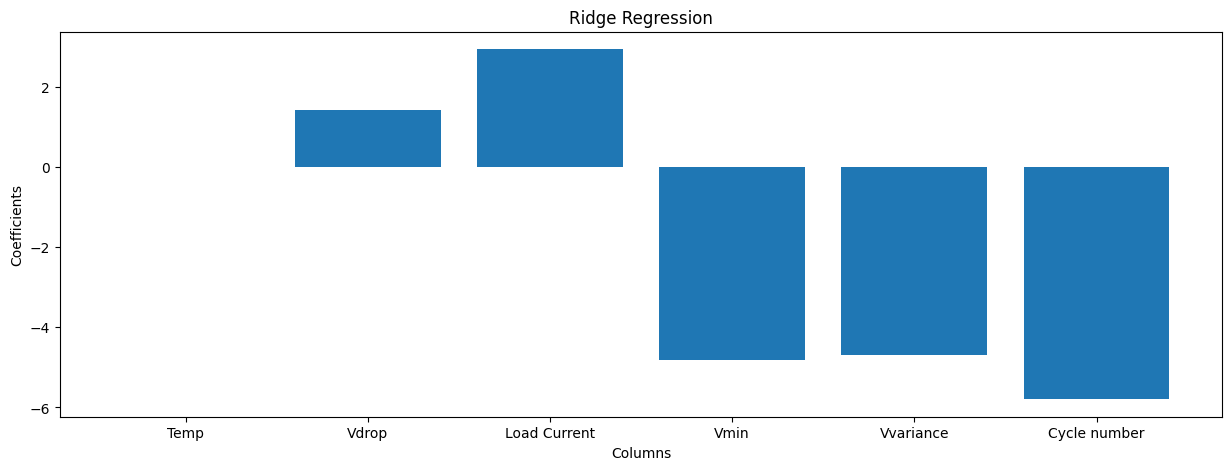

In [129]:
# Plot/display the coefficients
plt.figure(figsize=(15,5))
plt.bar(x.columns, ri.coef_)
plt.title('Ridge Regression')
plt.xlabel('Columns')
plt.ylabel('Coefficients')
plt.show()

## 9. Lasso Regression (L1 Regularization)

Lasso Regression is a regularized regression technique that introduces an L1 penalty to the least-squares objective function.

The L1 penalty encourages coefficient sparsity and can reduce selected regression coefficients exactly to zero.

This characteristic makes Lasso useful for identifying a smaller subset of potentially informative predictors.

### Experimental Objectives

1. Apply L1 regularization to the selected battery measurements.
2. Investigate different alpha values.
3. Identify features with non-zero coefficients.
4. Examine the number of features eliminated by regularization.
5. Evaluate the predictive performance of the selected feature set.
6. Compare Lasso with Linear Regression and Ridge Regression.

### Expected Investigation

This experiment will investigate whether Lasso can identify a smaller set of battery operating parameters while maintaining acceptable SOH prediction performance.

In [147]:
la = Lasso(alpha=1)

la.fit(x_train, y_train)
la_r2 = la.score(x_test, y_test)
la_r2

0.6044298904455068

In [146]:
la_mse = mean_squared_error(y_test, la.predict(x_test))
la_mae = mean_absolute_error(y_test, la.predict(x_test))
la_rmse = np.sqrt(mean_squared_error(y_test, la.predict(x_test)))

print('Lasso MSE: ', la_mse)
print('Lasso MAE: ', la_mae)
print('Lasso RMSE: ', la_rmse)

Lasso MSE:  35.719390581367676
Lasso MAE:  4.689206228961295
Lasso RMSE:  5.976570135233726


In [138]:
la.coef_

array([ 0.        ,  0.        ,  0.        , -2.48105534, -1.4607817 ,
       -5.68286299])

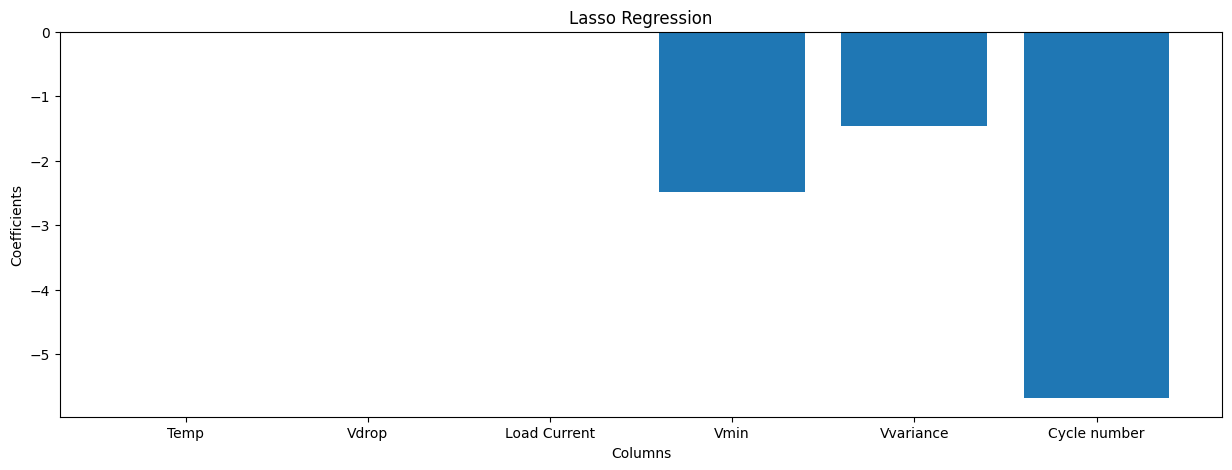

In [139]:
# Plot/display the coefficients
plt.figure(figsize=(15,5))
plt.bar(x.columns, la.coef_)
plt.title('Lasso Regression')
plt.xlabel('Columns')
plt.ylabel('Coefficients')
plt.show()

In [140]:
# compare the  coefficients of three models
df = pd.DataFrame({'col_name':x.columns, 'LinearRegression':lr.coef_, 'Lasso':la.coef_, 'Ridge':ri.coef_})
df

,col_name,LinearRegression,Lasso,Ridge
0,Temp,0.000000,0.000000,0.000000
1,Vdrop,1.458553,0.000000,1.412623
2,Load Current,3.024985,0.000000,2.931181
3,Vmin,-4.926397,-2.481055,-4.812056
4,Vvariance,-4.825375,-1.460782,-4.693781
5,Cycle number,-5.822501,-5.682863,-5.793820


## 10. Model Evaluation and Comparison

The predictive performance of Linear Regression, Ridge Regression, and Lasso Regression will be evaluated using consistent performance metrics.

Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and the coefficient of determination (R²) will be used to assess prediction accuracy and explanatory performance.

The comparison will help determine whether regularization improves predictive performance and whether coefficient shrinkage or feature selection provides practical benefits.

### Evaluation Criteria

- Lower MAE indicates smaller average absolute prediction errors.
- Lower RMSE indicates smaller prediction errors while penalizing larger errors more strongly.
- Higher R² indicates a greater proportion of target variance explained by the model.


In [148]:
# compare the evaluation metrics of three models
df = pd.DataFrame({'Models':['Linear Regression', 'Lasso', 'Ridge'], 
                   'MAE':[lr_mae, la_mae, ri_mae], 
                   'MSE':[lr_mse, la_mse, ri_mse], 
                   'RMSE':[lr_rmse, la_rmse, ri_rmse],
                   'R^2':[lr_r2, la_r2, ri_r2]})
df

,Models,MAE,MSE,RMSE,R^2
0,Linear Regression,3.983752,26.839722,5.180707,0.702767
1,Lasso,4.689206,35.719391,5.976570,0.604430
2,Ridge,3.996056,26.833747,5.180130,0.702833


## 11.Results and Discussion

### 1. Model Evaluation & Performance Comparison

Three regression models—Ordinary Least Squares (**Linear Regression**), **Lasso Regression** ($L_1$ regularization), and **Ridge Regression** ($L_2$ regularization)—were trained and evaluated to predict Lithium-Ion Battery State-of-Health (`Soh`) using operational and electrochemical degradation features.

#### Performance Analysis
* **Best Overall Predictive Performance (Ridge Regression):** Ridge achieved the lowest **RMSE (5.1801)** and **MSE (26.8337)** alongside the highest **$R^2$ (0.7028)**, explaining approximately **70.28%** of the variance in battery State-of-Health. Its metrics closely mirror standard Linear Regression (MAE: 3.9961 vs. 3.9838), indicating that while the baseline linear fit is stable, gentle $L_2$ coefficient shrinkage improves generalization by mitigating minor multicollinearity among voltage- and current-derived features.

* **Underfitting in Lasso Regression:** Lasso exhibited a noticeable drop in predictive accuracy, with **$R^2$ decreasing to 0.6044** and **RMSE rising to 5.9766** (+15.4% error increase over Ridge). Because $L_1$ regularization aggressively penalizes smaller weights to zero, Lasso discarded secondary operational features (`Vdrop` and `Load Current`) that carry meaningful explanatory power for `Soh`, introducing regularization-induced bias.

---

### 2. Key Findings & Physical Interpretation

1. **Cycle Aging is the Dominant Predictor (`Cycle number`):**
   * Across all three models, `Cycle number` holds the largest magnitude negative coefficient (**-5.8225** in Linear, **-5.6829** in Lasso, and **-5.7938** in Ridge). Even under strict $L_1$ regularization, this weight remains virtually unchanged, confirming that cumulative charge-discharge cycling—driven by Solid Electrolyte Interphase (SEI) layer growth and loss of active lithium inventory—is the primary linear driver of capacity fade.

2. **Voltage Dynamics Strongly Reflect Internal Degradation (`Vmin` & `Vvariance`):**
   * `Vmin` (**-4.8121** in Ridge) and `Vvariance` (**-4.6938** in Ridge) are the second and third strongest predictors. Higher voltage variance during discharge cycles reflects non-uniform voltage decay caused by rising internal impedance and polarization effects as the cell ages.
   * Notably, both `Vmin` and `Vvariance` exhibit negative weights, indicating that shifts in discharge voltage profiles and wider voltage fluctuations strongly correlate with declining `Soh`.

3. **Zero Contribution of Temperature (`Temp = 0.0000`):**
   * All three algorithms—including unregularized Linear Regression—assigned an exact weight of **0.0000** to `Temp`. This occurs when the dataset was collected under a controlled, constant ambient temperature (zero feature variance) or when `Temp` is completely collinear with another feature, providing zero marginal information for `Soh` estimation.

4. **Trade-off Between Feature Sparsity and Accuracy (`Load Current` & `Vdrop`):**
   * Lasso shrunk `Load Current` and `Vdrop` to exactly **0.0000**, leaving a compact 3-feature model (`Cycle number`, `Vmin`, `Vvariance`). While this demonstrates Lasso's utility for identifying the core degradation subset, the resulting ~9.8% drop in $R^2$ (0.7028 $\rightarrow$ 0.6044) proves that `Load Current` (**+2.9312** in Ridge) and `Vdrop` (**+1.4126** in Ridge) are necessary to contextualize voltage behavior under varying load conditions.

---

### 3. Limitations & Future Work

* **Capturing Non-Linear Degradation:** Linear models explain ~70.3% of `Soh` variance, leaving ~29.7% unexplained. Lithium-ion battery degradation typically exhibits non-linear behavior—particularly near the "knee point" where capacity fade accelerates rapidly. Introducing polynomial features or non-linear models (e.g., Random Forest, XGBoost, Support Vector Regression, or LSTM networks) is recommended to capture these higher-order electrochemical dynamics.